# Day 1: TCGA-BRCA data loading, cleaning and overall survival (cBioPortal files)

**Goal:** one clean table (patients x genes + survival) and a Kaplan-Meier curve for the whole cohort.

- `OS` = 1 means death, 0 means censored (alive at last follow-up)
- `OS.time` = days from diagnosis to death or last follow-up
- Sample ID `TCGA-XX-XXXX-01`: characters 14-15 are the sample type (`01` = primary tumor, `11` = normal)

**Files needed in `data/`:** `data_mrna_seq_tpm.txt`, `data_clinical_patient.txt`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from lifelines import KaplanMeierFitter

DATA = Path("../data")
FIGS = Path("../results/figures")
FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the raw files

In [2]:
# Expression: rows = genes, columns = samples. First two columns are gene identifiers.
expr = pd.read_csv(DATA / "data_mrna_seq_tpm.txt", sep="\t", comment="#")
print("raw expression table:", expr.shape)
print(expr.iloc[:3, :5])

raw expression table: (40796, 1098)
   Entrez_Gene_Id  TCGA-3C-AAAU-01A  TCGA-3C-AALI-01A  TCGA-3C-AALJ-01A  \
0               1            0.6030            0.6817            0.4499   
1              10            1.9286           12.5879            0.1077   
2             100            7.7496            9.4788           14.2387   

   TCGA-3C-AALK-01A  
0            0.2768  
1            1.1653  
2            6.4433  


In [3]:
# Clinical (patient level). cBioPortal files start with '#' comment lines.
clin = pd.read_csv(DATA / "data_clinical_patient.txt", sep="\t", comment="#")
print("clinical table:", clin.shape)
print(clin.columns.tolist())
clin[["PATIENT_ID", "OS_STATUS", "OS_MONTHS"]].head()

clinical table: (1098, 31)
['PATIENT_ID', 'AGE', 'AJCC_STAGING_EDITION', 'BIOPSY_SITE', 'DAYS_LAST_FOLLOWUP', 'DAYS_TO_BIRTH', 'DAYS_TO_DEATH', 'DISEASE_TYPE', 'ETHNICITY', 'ICD_10', 'MORPHOLOGY', 'OTHER_PATIENT_ID', 'PATH_M_STAGE', 'PATH_N_STAGE', 'PATH_STAGE', 'PATH_T_STAGE', 'PRIMARY_DIAGNOSIS', 'PRIMARY_SITE_PATIENT', 'PRIOR_MALIGNANCY', 'PRIOR_TREATMENT', 'RACE', 'SEX', 'VITAL_STATUS', 'YEAR_OF_DIAGNOSIS', 'OS_STATUS', 'OS_MONTHS', 'DFS_STATUS', 'DFS_MONTHS', 'PROJECT_ID', 'PROJECT_NAME', 'PROJECT_STATE']


,PATIENT_ID,OS_STATUS,OS_MONTHS
0,TCGA-3C-AAAU,0:LIVING,132.950066
1,TCGA-3C-AALI,0:LIVING,131.570302
2,TCGA-3C-AALJ,0:LIVING,48.423127
3,TCGA-3C-AALK,0:LIVING,47.568988
4,TCGA-4H-AAAK,0:LIVING,11.432326


## 2. Tidy the expression matrix
Use gene symbols as the index, merge duplicated symbols, and convert TPM to log2(TPM + 1).

In [6]:
import urllib.request

# 1. Get the NCBI human gene table (Entrez ID -> gene symbol). Downloaded once, about 10 MB.
gene_info_path = DATA / "Homo_sapiens.gene_info.gz"
if not gene_info_path.exists():
    url = "https://ftp.ncbi.nlm.nih.gov/gene/DATA/GENE_INFO/Mammalia/Homo_sapiens.gene_info.gz"
    urllib.request.urlretrieve(url, gene_info_path)

gi = pd.read_csv(gene_info_path, sep="\t", usecols=["GeneID", "Symbol", "type_of_gene"])
gi = gi[gi["Symbol"] != "-"].drop_duplicates("GeneID")
id2symbol = gi.set_index("GeneID")["Symbol"]

# 2. Map Entrez IDs to symbols
expr = expr.dropna(subset=["Entrez_Gene_Id"])
expr["gene"] = expr["Entrez_Gene_Id"].astype(int).map(id2symbol)
print("genes without a symbol (dropped):", expr["gene"].isna().sum())

expr = expr.dropna(subset=["gene"]).drop(columns=["Entrez_Gene_Id"])
expr = expr.set_index("gene").astype("float32")

# 3. Merge duplicated symbols, then TPM -> log2(TPM + 1)
print("duplicated gene symbols:", expr.index.duplicated().sum())
expr = expr.groupby(level=0).mean()
expr = np.log2(expr + 1)

print("expression (genes x samples):", expr.shape)
print(expr.index[:5].tolist())

genes without a symbol (dropped): 31
duplicated gene symbols: 34
expression (genes x samples): (40731, 1097)
['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1']


## 3. Clean the survival table

In [7]:
log = {"start (patients)": len(clin)}

# OS_STATUS looks like '1:DECEASED' / '0:LIVING'
clin = clin.dropna(subset=["OS_STATUS", "OS_MONTHS"]).copy()
clin["OS"] = clin["OS_STATUS"].astype(str).str.split(":").str[0].astype(int)
clin["OS_MONTHS"] = pd.to_numeric(clin["OS_MONTHS"], errors="coerce")
clin["OS.time"] = clin["OS_MONTHS"] * 30.4375          # months -> days
log["has OS status and time"] = len(clin)

clin = clin[clin["OS.time"] > 0]
log["OS.time > 0"] = len(clin)

clin = clin.drop_duplicates(subset="PATIENT_ID").set_index("PATIENT_ID")
log["one row per patient"] = len(clin)
pd.Series(log, name="patients remaining")

start (patients)          1098
has OS status and time    1097
OS.time > 0               1076
one row per patient       1076
Name: patients remaining, dtype: int64

## 4. Keep primary tumor samples and match to survival

In [8]:
samples = pd.Series(expr.columns, name="sample")
types = samples.str[13:15]
print(types.value_counts(), "\n")

primary = samples[types == "01"].tolist()
print("primary tumor samples:", len(primary))

# one primary sample per patient
sample_df = pd.DataFrame({"sample": primary})
sample_df["PATIENT_ID"] = sample_df["sample"].str[:12]
sample_df = sample_df.sort_values("sample").drop_duplicates("PATIENT_ID")
print("patients with a primary tumor sample:", len(sample_df))

sample_df = sample_df[sample_df["PATIENT_ID"].isin(clin.index)]
print("... and valid survival data:", len(sample_df))

# drop genes that are zero in every kept sample
expr = expr[sample_df["sample"]]
expr = expr.loc[(expr > 0).any(axis=1)]
print("genes kept:", expr.shape[0])

sample
01    1090
06       7
Name: count, dtype: int64 

primary tumor samples: 1090
patients with a primary tumor sample: 1090
... and valid survival data: 1068
genes kept: 39452


## 5. Build the analysis table (patients x genes) and save it

In [9]:
X = expr.T
X.index = sample_df["PATIENT_ID"].values
X.index.name = "patient"

y = clin.loc[X.index, ["OS", "OS.time"]].copy()

assert X.index.equals(y.index), "Index mismatch between X and y"
assert X.isna().sum().sum() == 0, "NaNs in expression"

print("X:", X.shape, "| y:", y.shape)
print(f"Events: {y['OS'].sum()} deaths ({y['OS'].mean():.1%}), median follow-up: {y['OS.time'].median()/365.25:.1f} years")

DATA.joinpath("processed").mkdir(exist_ok=True)
X.to_pickle(DATA / "processed" / "X_expression.pkl")
y.to_pickle(DATA / "processed" / "y_survival.pkl")

X: (1068, 39452) | y: (1068, 2)
Events: 149 deaths (14.0%), median follow-up: 2.4 years


## 6. Kaplan-Meier curve for the whole cohort

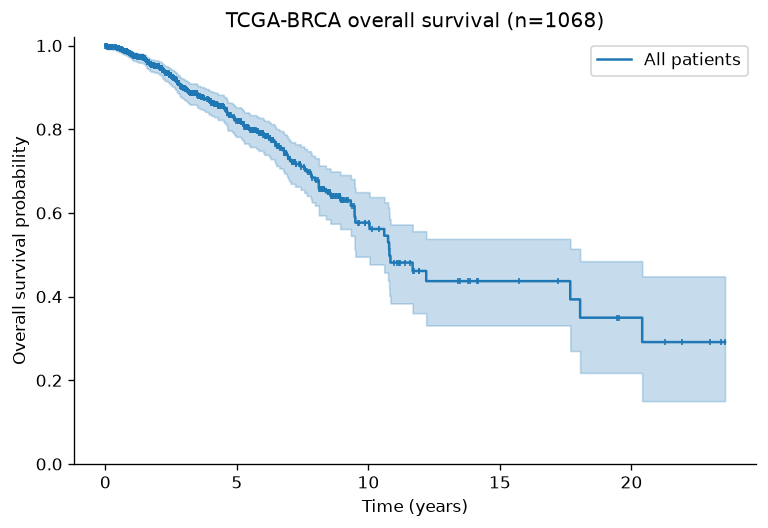

Median survival (years): 10.79993429697766
5-year survival: 0.8200632536411856


In [10]:
kmf = KaplanMeierFitter()
kmf.fit(y["OS.time"] / 365.25, event_observed=y["OS"], label="All patients")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
kmf.plot_survival_function(ax=ax, ci_show=True, show_censors=True,
                           censor_styles={"ms": 4, "marker": "|"})
ax.set_xlabel("Time (years)")
ax.set_ylabel("Overall survival probability")
ax.set_title(f"TCGA-BRCA overall survival (n={len(y)})")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig(FIGS / "km_overall.png", dpi=200)
plt.show()

print("Median survival (years):", kmf.median_survival_time_)
print("5-year survival:", float(kmf.predict(5)))

### Reading the plot
- The curve drops with each death; the small ticks are censored patients.
- Breast cancer survival is long, so the median is often not reached (`inf`). That is normal.
- The tail beyond ~10 years has very few patients at risk, so interpret it with care.

**Next (Day 2):** clinical baseline with age + stage, Cox model, KM by stage.